In [3]:
# %% Cell 1 - Setup
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import numpy as np
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
# %% Cell 2 - Markov chain functions

block_size = 512
batch_size = 16
learning_rate = 0.001
weight_decay = 1e-3
dropout = 0.0
vocabulary_size = 2
eval_iters = 200
eval_interval = 500

def generate_transition_matrix(order, seed):
    if seed is not None:
        torch.manual_seed(seed)
    n_states = 2 ** order
    matrix = torch.rand((n_states, 2))
    row_sums = matrix.sum(dim=1, keepdim=True)
    matrix = matrix / row_sums
    return matrix

def generate_sequence(transition_matrix, order, length, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    sequence = torch.zeros(length, dtype=torch.long)
    for i in range(order):
        sequence[i] = torch.randint(0, 2, (1,))
    for i in range(order, length):
        state_idx = 0
        for j in range(order):
            state_idx = state_idx * 2 + sequence[i - order + j]
        probs = transition_matrix[int(state_idx)]
        sequence[i] = torch.bernoulli(probs[1])
    return sequence.tolist()

def estimate_matrix(sequence, order):
    num_states = 2 ** order
    counts = torch.zeros((num_states, 2))
    for i in range(len(sequence) - order):
        state = sequence[i:i + order]
        state_idx = int(''.join(map(str, state)), 2)
        next_bit = sequence[i + order]
        counts[state_idx, next_bit] += 1
    row_sums = counts.sum(dim=1, keepdim=True)
    row_sums[row_sums == 0] = 2
    return counts / row_sums

def generate_training_data(transition_matrix, order, sequence_length, num_sequences):
    sequences = []
    for i in range(num_sequences):
        sequence = generate_sequence(transition_matrix, order, sequence_length, i)
        sequences.append(torch.tensor(sequence, dtype=torch.long))
    return sequences

def get_batch(sequences, split='train'):
    n = int(0.9 * len(sequences))
    data = sequences[:n] if split == 'train' else sequences[n:]
    while True:
        seq_indices = torch.randint(len(data), (batch_size,))
        x_batch, y_batch = [], []
        for idx in seq_indices:
            sequence = data[idx]
            if len(sequence) >= block_size + 1:
                start_idx = torch.randint(0, len(sequence) - block_size, (1,))
                x_batch.append(sequence[start_idx:start_idx + block_size])
                y_batch.append(sequence[start_idx + 1:start_idx + block_size + 1])
        if len(x_batch) > 0:
            return torch.stack(x_batch).to(device), torch.stack(y_batch).to(device)

@torch.no_grad()
def estimate_loss(model, sequences):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(sequences, split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

def kl_divergence(chain1, chain2, epsilon=1e-10):
    defined_states = torch.sum(chain2, dim=1) > 0
    p = chain1[defined_states] + epsilon
    q = chain2[defined_states] + epsilon
    p = p / p.sum(dim=1, keepdim=True)
    q = q / q.sum(dim=1, keepdim=True)
    return torch.sum(p * torch.log(p / q)).item()

def mean_error(chain1, chain2):
    defined_states = torch.sum(chain2, dim=1) > 0
    return torch.mean(torch.abs(chain1[defined_states] - chain2[defined_states])).item()

In [5]:
# %% Cell 3 - Transformer model

class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2, -1) * C ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class BinaryTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(vocabulary_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocabulary_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(torch.arange(T, device=device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

print("Model defined.")

Model defined.


In [6]:
# %% Cell 4 - Evaluation function

def evaluate_model(model_path, order, output_lengths=[500, 1000, 2000, 5000], num_test_seeds=10):
    """Load a trained model, generate sequences, compare to ground truth."""
    
    checkpoint = torch.load(model_path, map_location=device)
    transition_matrix = torch.tensor(checkpoint['transition_matrix'])
    config = checkpoint['config']
    
    # Set architecture globals
    global n_head, n_layer, n_embd
    n_head = config['n_head']
    n_layer = config['n_layer']
    n_embd = config['n_embd']
    
    # Load model
    model = BinaryTransformer().to(device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    
    results = []
    
    for output_length in output_lengths:
        klds = []
        maes = []
        
        for seed in range(200, 200 + num_test_seeds):
            # Generate context from true chain
            context = generate_sequence(transition_matrix, order, 50, seed)
            context_tensor = torch.tensor(context, dtype=torch.long).unsqueeze(0).to(device)
            
            # Generate output
            with torch.no_grad():
                generated = model.generate(context_tensor, output_length)
            output = generated.tolist()[0][50:]
            
            # Estimate transition matrix from output
            estimated = estimate_matrix(output, order)
            klds.append(kl_divergence(transition_matrix, estimated))
            maes.append(mean_error(transition_matrix, estimated))
        
        results.append({
            'output_length': output_length,
            'kld_mean': np.mean(klds), 'kld_std': np.std(klds),
            'mae_mean': np.mean(maes), 'mae_std': np.std(maes),
        })
    
    return {
        'config': config,
        'entropy_rate': config['entropy_rate'],
        'final_loss': checkpoint['history']['train'][-1],
        'results': results,
    }

print("Evaluation function defined.")

Evaluation function defined.


In [ ]:
# %% Cell 5 - Evaluate all models

models_dir = os.path.expanduser('../models/exp1')
results_dir = os.path.expanduser('../results/data_scaling')
Path(results_dir).mkdir(parents=True, exist_ok=True)

all_eval = {}

for setting in ['moritz', 'scaled']:
    all_eval[setting] = {}
    
    for order in [1, 2, 3, 4, 5, 6]:
        model_dir = Path(f"{models_dir}/{setting}/order{order}")
        model_files = sorted(model_dir.glob('*.pt'))
        
        print(f"\n{'='*60}")
        print(f"Evaluating: {setting} — Order {order} ({len(model_files)} models)")
        print(f"{'='*60}")
        
        all_eval[setting][order] = []
        
        for i, mf in enumerate(model_files):
            print(f"  Model {i+1}/{len(model_files)}: {mf.name}")
            result = evaluate_model(mf, order)
            all_eval[setting][order].append(result)

# Save results
import json

save_data = {}
for setting in all_eval:
    save_data[setting] = {}
    for order in all_eval[setting]:
        save_data[setting][str(order)] = []
        for r in all_eval[setting][order]:
            save_data[setting][str(order)].append({
                'config': r['config'],
                'entropy_rate': r['entropy_rate'],
                'final_loss': r['final_loss'],
                'results': r['results'],
            })

with open(f'{results_dir}/evaluation_results.json', 'w') as f:
    json.dump(save_data, f, indent=2)

print("\n\nALL EVALUATION COMPLETE!")
print(f"Results saved to {results_dir}/evaluation_results.json")


Evaluating: moritz — Order 1 (10 models)
  Model 1/10: model_o1_m0.pt


In [8]:
import json

with open(os.path.expanduser('../results/data_scaling/evaluation_results.json'), 'r') as f:
    data = json.load(f)

for setting in data:
    for order in data[setting]:
        n_models = len(data[setting][order])
        print(f"{setting} order {order}: {n_models} models evaluated")

moritz order 1: 10 models evaluated
moritz order 2: 10 models evaluated
moritz order 3: 10 models evaluated
moritz order 4: 10 models evaluated
moritz order 5: 10 models evaluated
moritz order 6: 10 models evaluated
scaled order 1: 10 models evaluated
scaled order 2: 10 models evaluated
scaled order 3: 10 models evaluated
scaled order 4: 10 models evaluated
scaled order 5: 10 models evaluated
scaled order 6: 10 models evaluated


In [9]:
# %% Comparison table: Moritz vs Scaled at output_length=1000

print("KL DIVERGENCE — Moritz vs Scaled (output_length=1000)")
print(f"{'Order':<7} {'Moritz KLD':<20} {'Scaled KLD':<20} {'Improvement':<15}")
print("-" * 62)

for order in ['1', '2', '3', '4', '5', '6']:
    moritz_klds = []
    scaled_klds = []
    
    for model_result in data['moritz'][order]:
        for r in model_result['results']:
            if r['output_length'] == 1000:
                moritz_klds.append(r['kld_mean'])
    
    for model_result in data['scaled'][order]:
        for r in model_result['results']:
            if r['output_length'] == 1000:
                scaled_klds.append(r['kld_mean'])
    
    m_mean = np.mean(moritz_klds)
    s_mean = np.mean(scaled_klds)
    improvement = ((m_mean - s_mean) / m_mean) * 100 if m_mean > 0 else 0
    
    print(f"{order:<7} {m_mean:.4f} ± {np.std(moritz_klds):.4f}   {s_mean:.4f} ± {np.std(scaled_klds):.4f}   {improvement:+.1f}%")

print("\n\nMAE — Moritz vs Scaled (output_length=1000)")
print(f"{'Order':<7} {'Moritz MAE':<20} {'Scaled MAE':<20} {'Improvement':<15}")
print("-" * 62)

for order in ['1', '2', '3', '4', '5', '6']:
    moritz_maes = []
    scaled_maes = []
    
    for model_result in data['moritz'][order]:
        for r in model_result['results']:
            if r['output_length'] == 1000:
                moritz_maes.append(r['mae_mean'])
    
    for model_result in data['scaled'][order]:
        for r in model_result['results']:
            if r['output_length'] == 1000:
                scaled_maes.append(r['mae_mean'])
    
    m_mean = np.mean(moritz_maes)
    s_mean = np.mean(scaled_maes)
    improvement = ((m_mean - s_mean) / m_mean) * 100 if m_mean > 0 else 0
    
    print(f"{order:<7} {m_mean:.4f} ± {np.std(moritz_maes):.4f}   {s_mean:.4f} ± {np.std(scaled_maes):.4f}   {improvement:+.1f}%")

KL DIVERGENCE — Moritz vs Scaled (output_length=1000)
Order   Moritz KLD           Scaled KLD           Improvement    
--------------------------------------------------------------
1       0.0034 ± 0.0015   0.0034 ± 0.0015   +0.0%
2       0.0284 ± 0.0284   0.0875 ± 0.0783   -208.4%
3       0.1809 ± 0.1687   0.2666 ± 0.5848   -47.4%
4       1.0769 ± 0.7958   0.8406 ± 0.5121   +21.9%
5       4.3634 ± 3.9849   4.5599 ± 4.3845   -4.5%
6       26.7191 ± 11.8080   23.0819 ± 9.5917   +13.6%


MAE — Moritz vs Scaled (output_length=1000)
Order   Moritz MAE           Scaled MAE           Improvement    
--------------------------------------------------------------
1       0.0190 ± 0.0033   0.0190 ± 0.0033   +0.0%
2       0.0357 ± 0.0132   0.0677 ± 0.0366   -89.3%
3       0.0690 ± 0.0347   0.0503 ± 0.0255   +27.0%
4       0.0872 ± 0.0376   0.0947 ± 0.0391   -8.6%
5       0.0798 ± 0.0127   0.0816 ± 0.0188   -2.3%
6       0.1293 ± 0.0318   0.1272 ± 0.0314   +1.6%


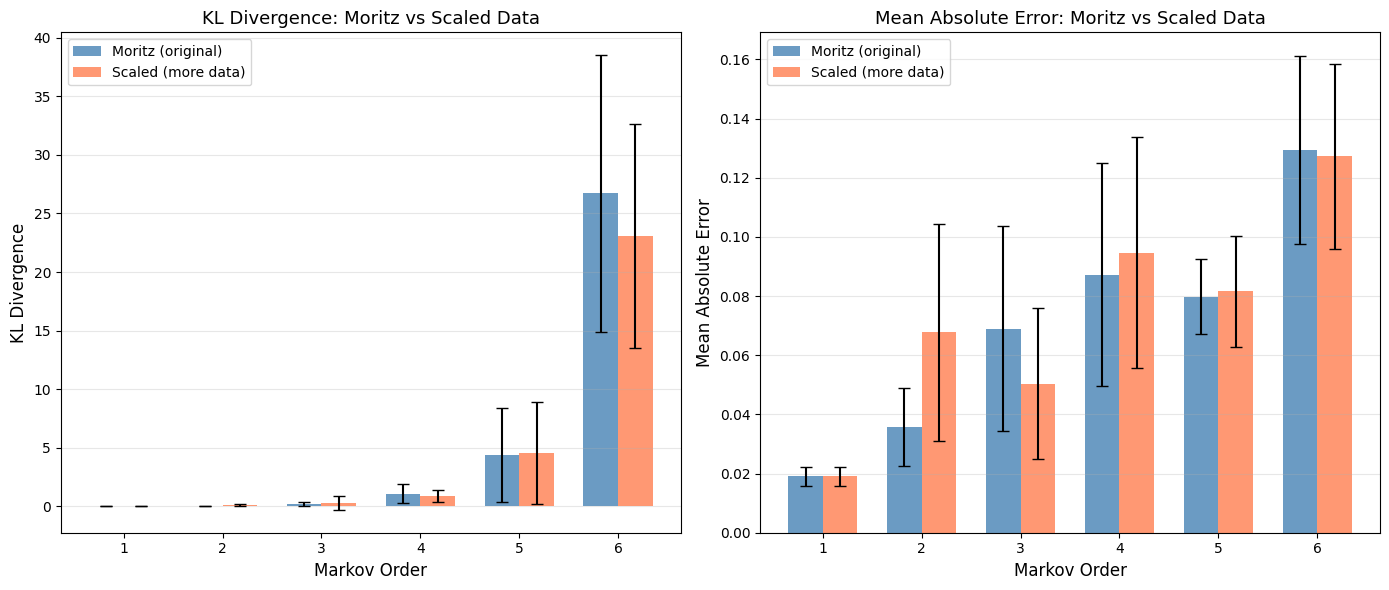

Plot saved!


In [10]:
# %% Plot: Moritz vs Scaled comparison

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

orders = [1, 2, 3, 4, 5, 6]

for ax, metric, label in [(axes[0], 'kld', 'KL Divergence'), (axes[1], 'mae', 'Mean Absolute Error')]:
    moritz_means = []
    moritz_stds = []
    scaled_means = []
    scaled_stds = []
    
    for order in orders:
        m_vals = []
        s_vals = []
        for model_result in data['moritz'][str(order)]:
            for r in model_result['results']:
                if r['output_length'] == 1000:
                    m_vals.append(r[f'{metric}_mean'])
        for model_result in data['scaled'][str(order)]:
            for r in model_result['results']:
                if r['output_length'] == 1000:
                    s_vals.append(r[f'{metric}_mean'])
        
        moritz_means.append(np.mean(m_vals))
        moritz_stds.append(np.std(m_vals))
        scaled_means.append(np.mean(s_vals))
        scaled_stds.append(np.std(s_vals))
    
    moritz_means = np.array(moritz_means)
    moritz_stds = np.array(moritz_stds)
    scaled_means = np.array(scaled_means)
    scaled_stds = np.array(scaled_stds)
    
    x = np.arange(len(orders))
    width = 0.35
    
    ax.bar(x - width/2, moritz_means, width, yerr=moritz_stds, 
           label='Moritz (original)', color='steelblue', capsize=4, alpha=0.8)
    ax.bar(x + width/2, scaled_means, width, yerr=scaled_stds,
           label='Scaled (more data)', color='coral', capsize=4, alpha=0.8)
    
    ax.set_xlabel('Markov Order', fontsize=12)
    ax.set_ylabel(label, fontsize=12)
    ax.set_title(f'{label}: Moritz vs Scaled Data', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(orders)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.expanduser('../plots/../plots/exp1_moritz_vs_scaled.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

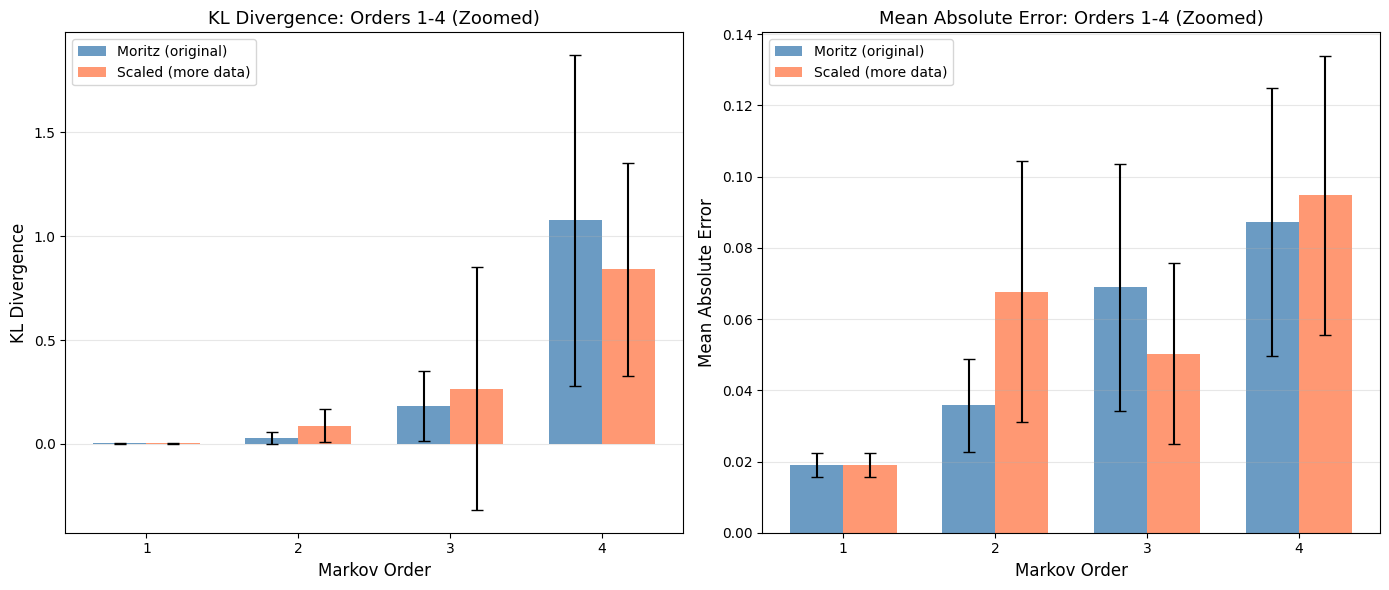

Plot saved!


In [11]:
# %% Plot: Zoomed into orders 1-4

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

orders_zoom = [1, 2, 3, 4]

for ax, metric, label in [(axes[0], 'kld', 'KL Divergence'), (axes[1], 'mae', 'Mean Absolute Error')]:
    moritz_means = []
    moritz_stds = []
    scaled_means = []
    scaled_stds = []
    
    for order in orders_zoom:
        m_vals = []
        s_vals = []
        for model_result in data['moritz'][str(order)]:
            for r in model_result['results']:
                if r['output_length'] == 1000:
                    m_vals.append(r[f'{metric}_mean'])
        for model_result in data['scaled'][str(order)]:
            for r in model_result['results']:
                if r['output_length'] == 1000:
                    s_vals.append(r[f'{metric}_mean'])
        
        moritz_means.append(np.mean(m_vals))
        moritz_stds.append(np.std(m_vals))
        scaled_means.append(np.mean(s_vals))
        scaled_stds.append(np.std(s_vals))
    
    moritz_means = np.array(moritz_means)
    moritz_stds = np.array(moritz_stds)
    scaled_means = np.array(scaled_means)
    scaled_stds = np.array(scaled_stds)
    
    x = np.arange(len(orders_zoom))
    width = 0.35
    
    ax.bar(x - width/2, moritz_means, width, yerr=moritz_stds,
           label='Moritz (original)', color='steelblue', capsize=4, alpha=0.8)
    ax.bar(x + width/2, scaled_means, width, yerr=scaled_stds,
           label='Scaled (more data)', color='coral', capsize=4, alpha=0.8)
    
    ax.set_xlabel('Markov Order', fontsize=12)
    ax.set_ylabel(label, fontsize=12)
    ax.set_title(f'{label}: Orders 1-4 (Zoomed)', fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels(orders_zoom)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.expanduser('../plots/../plots/exp1_zoomed_orders1to4.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")